In [55]:
# Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
import io

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


In [56]:
# Import Dataset
# Direkter Download der CSV von einer zuverlässigen Quelle (UCI/GitHub)
url = "https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv"
s = requests.get(url).content
df = pd.read_csv(io.StringIO(s.decode('utf-8')))
df

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


In [57]:
# Datenvorbereitung: Label Encoding, Feature Scaling, Train-Test Split
# 1. Label Encoding (Target aufbereiten)
le = LabelEncoder()
df['variety'] = le.fit_transform(df['variety'])

# 2. Feature Scaling (Inputs transformieren)
# Wir skalieren ALLES, bevor wir splitten (einfacher für den Einstieg)
scaler = StandardScaler()
X_all = df.drop('variety', axis=1)
X_scaled = scaler.fit_transform(X_all)
y_all = df['variety'].values

# 3. Train-Test Split
# Jetzt nehmen wir die bereits transformierten Daten und teilen sie auf
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_all, test_size=0.2, random_state=42
)

# 4. Convert to PyTorch Tensors
# Erst wenn die Daten fertig portioniert sind, machen wir Tensoren daraus
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print(f"Training bereit: {X_train_t.shape}")

Training bereit: torch.Size([120, 4])


In [58]:
# Define Neural Network
class IrisNN(nn.Module):
    def __init__(self):
        super(IrisNN, self).__init__()
        self.fc1 = nn.Linear(4, 10)  # Input layer to hidden layer
        self.fc2 = nn.Linear(10, 3)  # Hidden layer to output layer
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [59]:
# Train the Neural Network
model = IrisNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [62]:
# Train with the training set, evalute with the test set
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    if (epoch+1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [20/100], Loss: 0.0450
Epoch [40/100], Loss: 0.0445
Epoch [60/100], Loss: 0.0441
Epoch [80/100], Loss: 0.0438
Epoch [100/100], Loss: 0.0435


In [63]:
# Evaluate the model on the test set
model.eval()
with torch.no_grad():
    outputs = model(X_test_t)
    _, predicted = torch.max(outputs, 1)
    accuracy = (predicted == y_test_t).float().mean()
print(f'Test Accuracy: {accuracy.item() * 100:.2f}%')

Test Accuracy: 100.00%


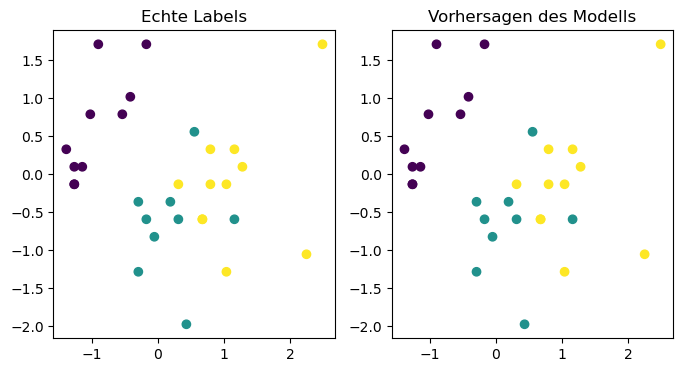

In [64]:
# Create graph of training and evaluation results
# (Hier könnte man z.B. den Loss-Verlauf über die Epochen plotten, oder die Vorhersagen vs. die echten Labels visualisieren)
# Beispiel: Vorhersagen vs. echte Labels
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, label='Echte Labels', cmap='viridis')
plt.title('Echte Labels')
plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=predicted.numpy(), label='Vorhersagen', cmap='viridis')
plt.title('Vorhersagen des Modells')
plt.show()